<a href="https://colab.research.google.com/github/mapsmania/3Dmap/blob/main/map_poster.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

🎨 Generating poster for Paris, France...
  - Fetching street network (this may take a minute)...
  - Fetching water and parks...
✅ Poster saved as posters/paris_20260118.png


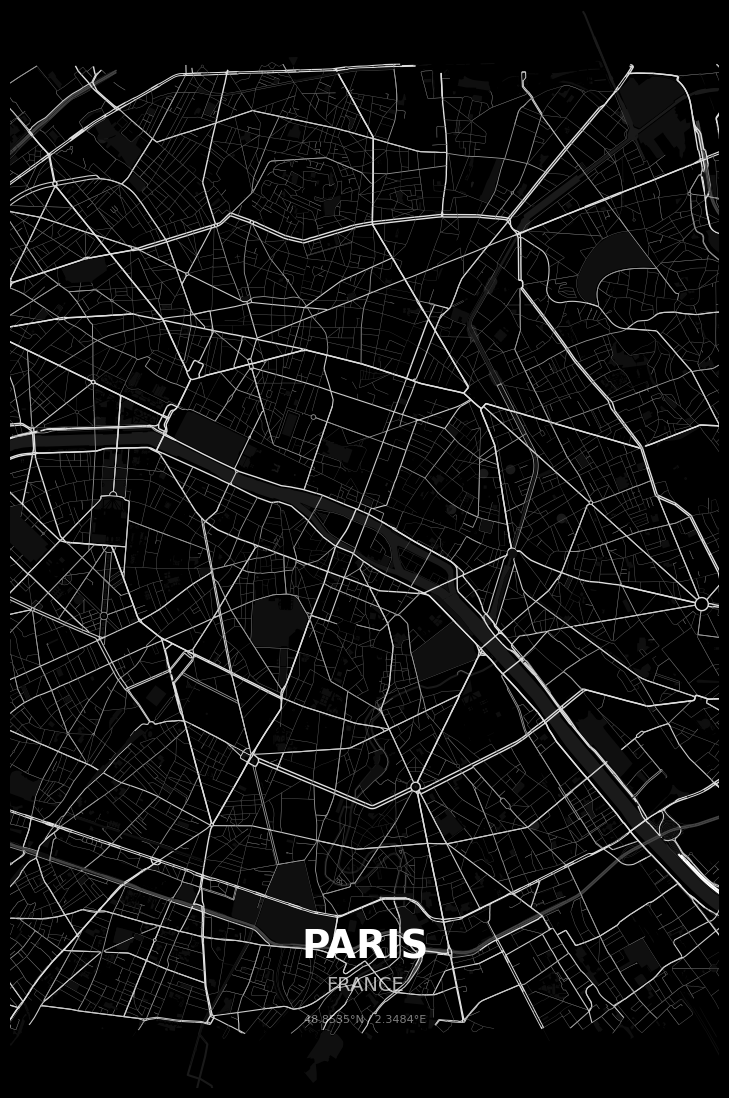

In [3]:
# 1. Install necessary libraries
!pip install osmnx matplotlib geographiclib

import os
import json
import osmnx as ox
import matplotlib.pyplot as plt
from matplotlib import patches
from datetime import datetime

# 2. Setup Folder Structure
os.makedirs('themes', exist_ok=True)
os.makedirs('posters', exist_ok=True)

# 3. Create a default theme file (Noir) so the script has something to read
default_theme = {
    "name": "Noir",
    "bg": "#000000",
    "text": "#FFFFFF",
    "water": "#1a1a1a",
    "parks": "#0f0f0f",
    "road_motorway": "#ffffff",
    "road_primary": "#e0e0e0",
    "road_secondary": "#cccccc",
    "road_tertiary": "#999999",
    "road_residential": "#666666",
    "road_default": "#444444"
}

with open('themes/noir.json', 'w') as f:
    json.dump(default_theme, f)

# 4. The Core Poster Generator Function
def create_map_poster(city, country, theme_path='themes/noir.json', dist=8000):
    print(f"🎨 Generating poster for {city}, {country}...")

    # Load Theme
    with open(theme_path, 'r') as f:
        theme = json.load(f)

    # Get Coordinates
    try:
        location = ox.geocoder.geocode(f"{city}, {country}")
        point = (location[0], location[1])
    except Exception as e:
        print(f"Error finding location: {e}")
        return

    # Fetch Data
    print("  - Fetching street network (this may take a minute)...")
    G = ox.graph_from_point(point, dist=dist, network_type='drive', retain_all=True)

    print("  - Fetching water and parks...")
    try:
        water = ox.features_from_point(point, tags={'natural': 'water', 'waterway': True}, dist=dist)
    except: water = None
    try:
        parks = ox.features_from_point(point, tags={'leisure': 'park', 'landuse': 'grass'}, dist=dist)
    except: parks = None

    # Setup Plot
    fig, ax = plt.subplots(figsize=(10, 14), facecolor=theme['bg'])
    ax.set_facecolor(theme['bg'])

    # Plot Water
    if water is not None and not water.empty:
        water.plot(ax=ax, color=theme['water'], zorder=1)

    # Plot Parks
    if parks is not None and not parks.empty:
        parks.plot(ax=ax, color=theme['parks'], zorder=2)

    # Plot Roads with hierarchy
    widths = {
        'motorway': 1.5, 'trunk': 1.2, 'primary': 1.0,
        'secondary': 0.8, 'tertiary': 0.6, 'residential': 0.3
    }

    # Helper function to handle potential list values for highway tags
    def get_single_highway_type(highway_tag):
        if isinstance(highway_tag, list):
            # If there are multiple highway types, pick the first one
            return highway_tag[0] if highway_tag else None
        return highway_tag

    # Helper to get edge widths/colors
    edge_widths = [widths.get(get_single_highway_type(d.get('highway')), 0.2) for _, _, d in G.edges(data=True)]
    edge_colors = [theme.get(f"road_{get_single_highway_type(d.get('highway'))}", theme['road_default']) for _, _, d in G.edges(data=True)]

    ox.plot_graph(G, ax=ax, node_size=0, edge_color=edge_colors,
                  edge_linewidth=edge_widths, show=False, close=False)

    # Styling the frame
    ax.set_xlim(point[1] - 0.05, point[1] + 0.05) # Approximate zoom
    ax.set_ylim(point[0] - 0.05, point[0] + 0.05)
    ax.axis('off')

    # Add Text
    plt.text(0.5, 0.12, city.upper(), transform=ax.transAxes, color=theme['text'],
             fontsize=28, ha='center', fontweight='bold')
    plt.text(0.5, 0.09, country.upper(), transform=ax.transAxes, color=theme['text'],
             fontsize=14, ha='center', alpha=0.7)
    plt.text(0.5, 0.06, f"{point[0]:.4f}°N / {point[1]:.4f}°E", transform=ax.transAxes,
             color=theme['text'], fontsize=8, ha='center', alpha=0.5)

    # Save
    filename = f"posters/{city.lower()}_{datetime.now().strftime('%Y%m%d')}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight', pad_inches=0)
    print(f"✅ Poster saved as {filename}")
    plt.show()

# 5. RUN IT
create_map_poster(city="Paris", country="France", dist=5000)
